# Exposure Bias in Large Recommenders — results

Amazon Reviews 2023 · Electronics · implicit ALS + z-scored popularity re-ranker.

This notebook **reads only `results/*.json`** (the artefacts of the pipeline run) and never
recomputes a metric. Each table below is the source for the matching table in `report/REPORT.md`.
Figures are regenerated with the same plotting functions as `scripts/06_report.py`.

In [1]:
import importlib.util
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "results").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RESULTS, FIGURES = ROOT / "results", ROOT / "figures"

def load(name, required=True):
    path = RESULTS / name
    if not path.exists():
        if required:
            raise FileNotFoundError(path)
        return None
    return json.loads(path.read_text(encoding="utf-8"))

funnel = load("prepare_funnel.json")
manifest = load("run_manifest.json")
baseline = load("baseline_metrics.json")
sweep = load("rerank_sweep.json")
sensitivity = load("sensitivity.json", required=False)
pd.set_option("display.float_format", lambda v: f"{v:,.6f}")
print("run", manifest["git_commit"][:7], "generated", manifest["generated_utc"])

run c15fbb8 generated 2026-11-02T13:48:11.009204+00:00


## 1. Run configuration

In [2]:
pd.Series({**manifest["params"], **manifest["packages"],
           "seed": manifest["seed"], "python": manifest["python"],
           "mean per-user score std": manifest["score_stats"]["mean_per_user_score_std"]},
          name="value").to_frame()

,value
factors,64
iterations,15
regularization,0.050000
alpha,40.000000
n_candidates,200
k,10
min_rating,4.000000
min_catalogue_interactions,3
min_train_positives_exposure,1
min_train_positives_relevance,2


## 2. Prepare funnel — how much catalogue survived to be protected

In [3]:
stages = pd.DataFrame(funnel["stages"]).set_index("stage")
stages

,users,items,interactions,sampled_users
stage,,,,
raw_reviews,18286191,1609860,43886944,NaN
positives_ge_4,14795065,1404832,33387473,NaN
non_positives_seen,6936503,953003,10499471,NaN
after_split,18286191,1609860,43886944,NaN
catalogue_ge_3,5935606,538448,538448,NaN
eval_exposure_pop,6062089,1140926,18592408,"300,000.000000"
eval_relevance_pop,3215295,1065632,15745614,"300,000.000000"


In [4]:
pd.Series({k: funnel[k] for k in
           ("positive_fraction", "store_null_rate", "test_items_outside_catalogue_frac")},
          name="value").to_frame()

,value
positive_fraction,0.760761
store_null_rate,0.005939
test_items_outside_catalogue_frac,0.515640


In [5]:
pop_buckets = pd.DataFrame(funnel["buckets"]).T
store_buckets = pd.DataFrame(funnel["store_buckets"]).T
display(pop_buckets)
display(store_buckets)
large, small = funnel["store_buckets"]["large"], funnel["store_buckets"]["small"]
gate = large["n_stores"] >= 100 and small["store_share"] <= 0.95
print("store mass-rule degeneracy gate:", "PASS" if gate else "FAIL — switch to a fixed percentile")

,n_items,item_share,interaction_share
head,"14,607.000000",0.027128,0.499992
mid,"85,926.000000",0.159581,0.300007
tail,"437,915.000000",0.813291,0.200001


,n_stores,store_share,item_share
large,"9,992.000000",0.154723,0.797236
small,"54,587.000000",0.845262,0.199299
unknown,1.000000,0.000015,0.003466


store mass-rule degeneracy gate: PASS


## 3. Baseline relevance and the MostPop gate

In [6]:
rel = pd.DataFrame({
    "ALS": baseline["relevance_pop"],
    "MostPop": baseline["baselines"]["mostpop"]["relevance_pop"],
    "Random": baseline["baselines"]["random"]["relevance_pop"],
}).T[["ndcg", "hitrate"]].astype(float)
rel

,ndcg,hitrate
ALS,0.013341,0.022937
MostPop,0.008741,0.017463
Random,0.000011,0.000023


In [7]:
als, mp, rnd = rel.loc["ALS", "ndcg"], rel.loc["MostPop", "ndcg"], rel.loc["Random", "ndcg"]
print(f"ALS beats MostPop on NDCG@10: {als > mp}  (+{als / mp - 1:.1%} relative)")
print(f"ALS edge over Random: {als - rnd:.6f} NDCG — the unit the re-ranking cost is expressed in")

ALS beats MostPop on NDCG@10: True  (+52.6% relative)
ALS edge over Random: 0.013330 NDCG — the unit the re-ranking cost is expressed in


## 4. Baseline exposure — popularity and seller buckets

In [8]:
rows = {}
for pop in ("exposure_pop", "relevance_pop"):
    b = baseline[pop]
    for bucket in ("head", "mid", "tail"):
        rows[(pop, bucket)] = {
            "exposure_share": b["exposure_share"][bucket],
            "item_share": funnel["buckets"][bucket]["item_share"],
            "parity": b["exposure_parity"][bucket],
        }
pd.DataFrame(rows).T

exposure_share  item_share    parity
exposure_pop  head        0.999553    0.027128 36.845849
              mid         0.000447    0.159581  0.002801
              tail        0.000000    0.813291  0.000000
relevance_pop head        0.999678    0.027128 36.850444
              mid         0.000322    0.159581  0.002020
              tail        0.000000    0.813291  0.000000

In [9]:
store = {}
for bucket in ("large", "small", "unknown"):
    share = baseline["exposure_pop"]["store_exposure_share"][bucket]
    item_share = funnel["store_buckets"][bucket]["item_share"]
    store[bucket] = {"exposure_share": share, "item_share": item_share,
                     "parity": share / item_share if item_share else 0.0}
display(pd.DataFrame(store).T)
print("store x popularity cross-tab (exposure pop):")
pd.DataFrame(baseline["exposure_pop"]["exposure_share_by_pop"]).T

,exposure_share,item_share,parity
large,0.986235,0.797236,1.237069
small,0.013765,0.199299,0.069066
unknown,0.000000,0.003466,0.000000


store x popularity cross-tab (exposure pop):


,small,large,unknown
head,0.013765,0.985788,0.000000
mid,0.000000,0.000447,0.000000
tail,0.000000,0.000000,0.000000


In [10]:
pd.DataFrame({pop: {k: baseline[pop].get(k) for k in
              ("coverage", "gini_popularity", "mean_recommended_popularity")}
              for pop in ("exposure_pop", "relevance_pop")})

,exposure_pop,relevance_pop
coverage,0.004550,0.004140
gini_popularity,0.999219,0.999196
mean_recommended_popularity,"11,350.868916","10,422.021678"


## 5. Re-ranking sweep — the cost curve

In [11]:
exp_rows = {r["lambda"]: r for r in sweep["exposure_pop"]}
table = pd.DataFrame([{
    "lambda": r["lambda"],
    "ndcg": r["ndcg"],
    "hitrate": r["hitrate"],
    "cost_frac_of_edge": -r["delta_ndcg_frac_of_als_minus_random"],
    "mean_rec_popularity": exp_rows[r["lambda"]]["mean_recommended_popularity"],
    "head": exp_rows[r["lambda"]]["exposure_share"]["head"],
    "mid": exp_rows[r["lambda"]]["exposure_share"]["mid"],
    "tail": exp_rows[r["lambda"]]["exposure_share"]["tail"],
    "small_store": exp_rows[r["lambda"]]["store_exposure_share"]["small"],
    "coverage": exp_rows[r["lambda"]]["coverage"],
    "gini": exp_rows[r["lambda"]]["gini_popularity"],
} for r in sweep["relevance_pop"]]).set_index("lambda")
table

,ndcg,hitrate,cost_frac_of_edge,mean_rec_popularity,head,mid,tail,small_store,coverage,gini
lambda,,,,,,,,,,
0.000000,0.013341,0.022937,-0.000000,"11,350.868916",0.999553,0.000447,0.000000,0.013765,0.004550,0.999219
0.100000,0.013283,0.022780,0.004371,"9,876.057125",0.999463,0.000537,0.000000,0.016776,0.005096,0.999122
0.250000,0.013207,0.022597,0.010050,"8,833.991771",0.999285,0.000715,0.000000,0.018219,0.005399,0.998975
0.500000,0.013055,0.022180,0.021479,"7,206.778086",0.998915,0.001085,0.000000,0.021322,0.006038,0.998656
1.000000,0.012371,0.020590,0.072802,"4,354.277543",0.997041,0.002959,0.000000,0.028962,0.007999,0.997604
2.000000,0.008684,0.013907,0.349363,"1,255.931172",0.991323,0.008677,0.000000,0.048073,0.010577,0.994860


In [12]:
base = table.loc[0.0]
for lam in (0.5, 2.0):
    row = table.loc[lam]
    print(f"lambda={lam}: cost {row.cost_frac_of_edge:.1%} of edge | "
          f"mean popularity {row.mean_rec_popularity / base.mean_rec_popularity - 1:+.1%} | "
          f"coverage {row.coverage / base.coverage - 1:+.1%} | "
          f"small-store share {base.small_store:.2%} -> {row.small_store:.2%} | "
          f"tail share {row['tail']:.4%}")
print("lambda=2 NDCG below MostPop:", table.loc[2.0, "ndcg"] < mp)
print("chosen_lambda in artefact:", sweep["chosen_lambda"])

lambda=0.5: cost 2.1% of edge | mean popularity -36.5% | coverage +32.7% | small-store share 1.38% -> 2.13% | tail share 0.0000%
lambda=2.0: cost 34.9% of edge | mean popularity -88.9% | coverage +132.4% | small-store share 1.38% -> 4.81% | tail share 0.0000%
lambda=2 NDCG below MostPop: True
chosen_lambda in artefact: None


**Reading.** Small λ is nearly free and cost accelerates past λ = 1. Exposure moves from
head to *mid*. Tail exposure stays at exactly 0 at every λ, because the re-ranker can only permute
ALS's top-200 candidates, and those contain essentially no tail items.

## 6. Sensitivity — γ-weighted (inverse-popularity) relevance

In [13]:
if sensitivity is None:
    print("sensitivity.json absent — section skipped")
else:
    block = sensitivity["relevance_pop"]
    sens = pd.DataFrame(block["metrics"]).T.astype(float)
    sens.index.name = "gamma"
    sens["ndcg_vs_gamma0"] = sens["ndcg"] / sens["ndcg"].iloc[0]
    display(sens)

,ndcg,hitrate,ndcg_vs_gamma0
gamma,,,
0.0,0.013341,0.022937,1.000000
0.25,0.004147,0.007389,0.310831
0.50,0.000997,0.001845,0.074726
0.75,0.000199,0.000382,0.014886
1.00,0.000036,0.000071,0.002665


Up-weighting users whose held-out item is unpopular collapses ALS's measured quality.
Observed-interaction NDCG is earned almost entirely on popular test items, so the re-ranking cost
in §5 is an **upper bound**.

## 7. Figures

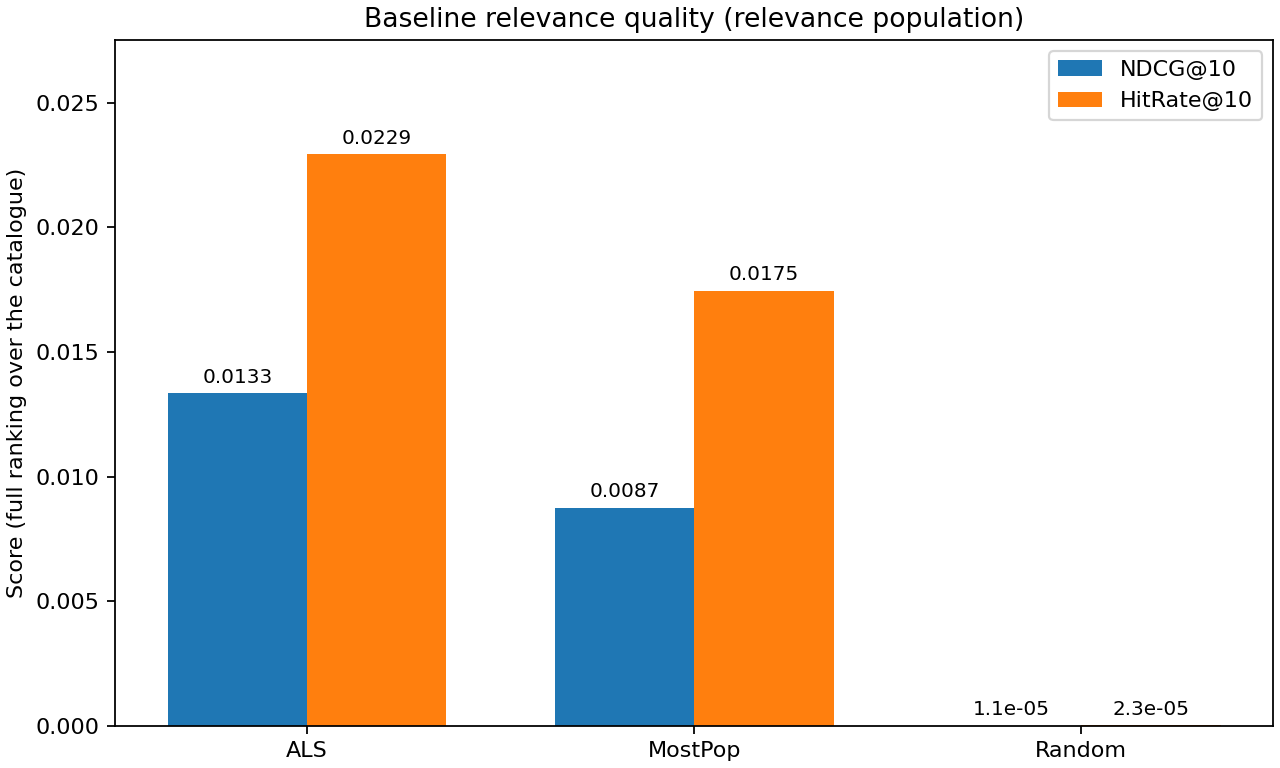

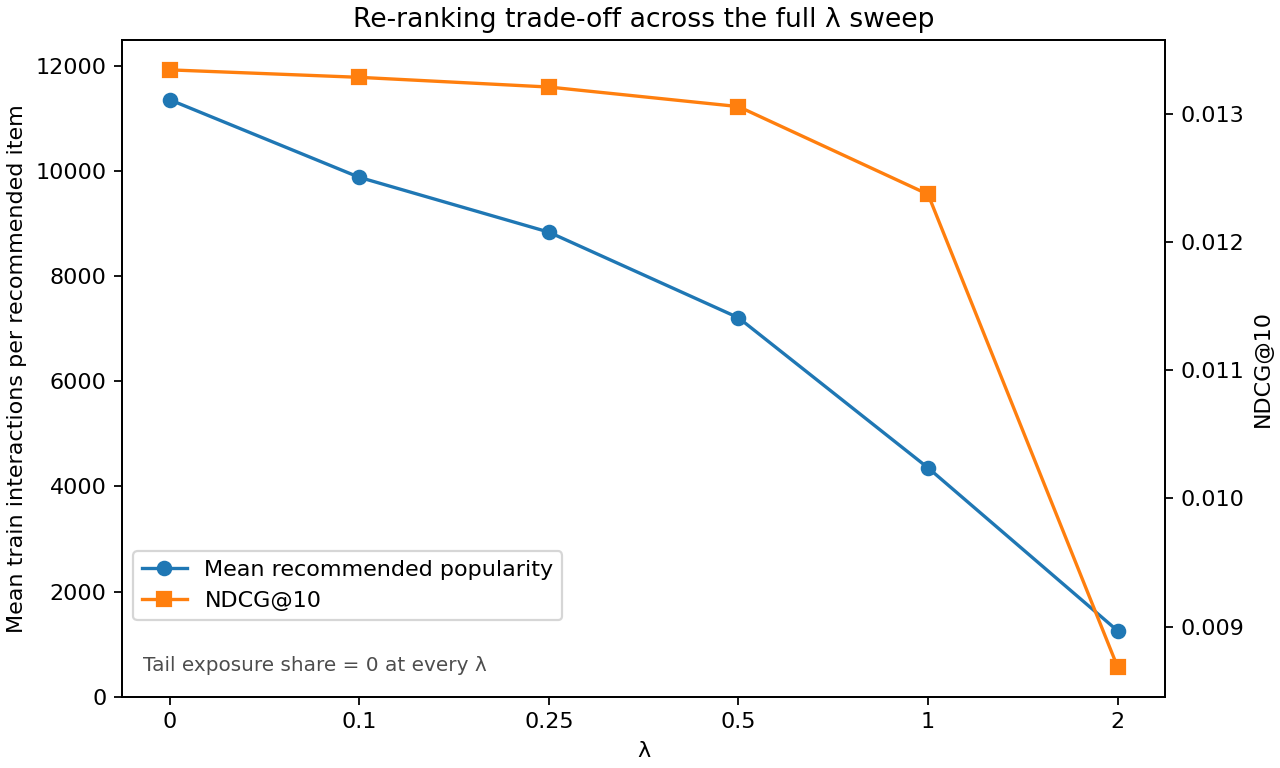

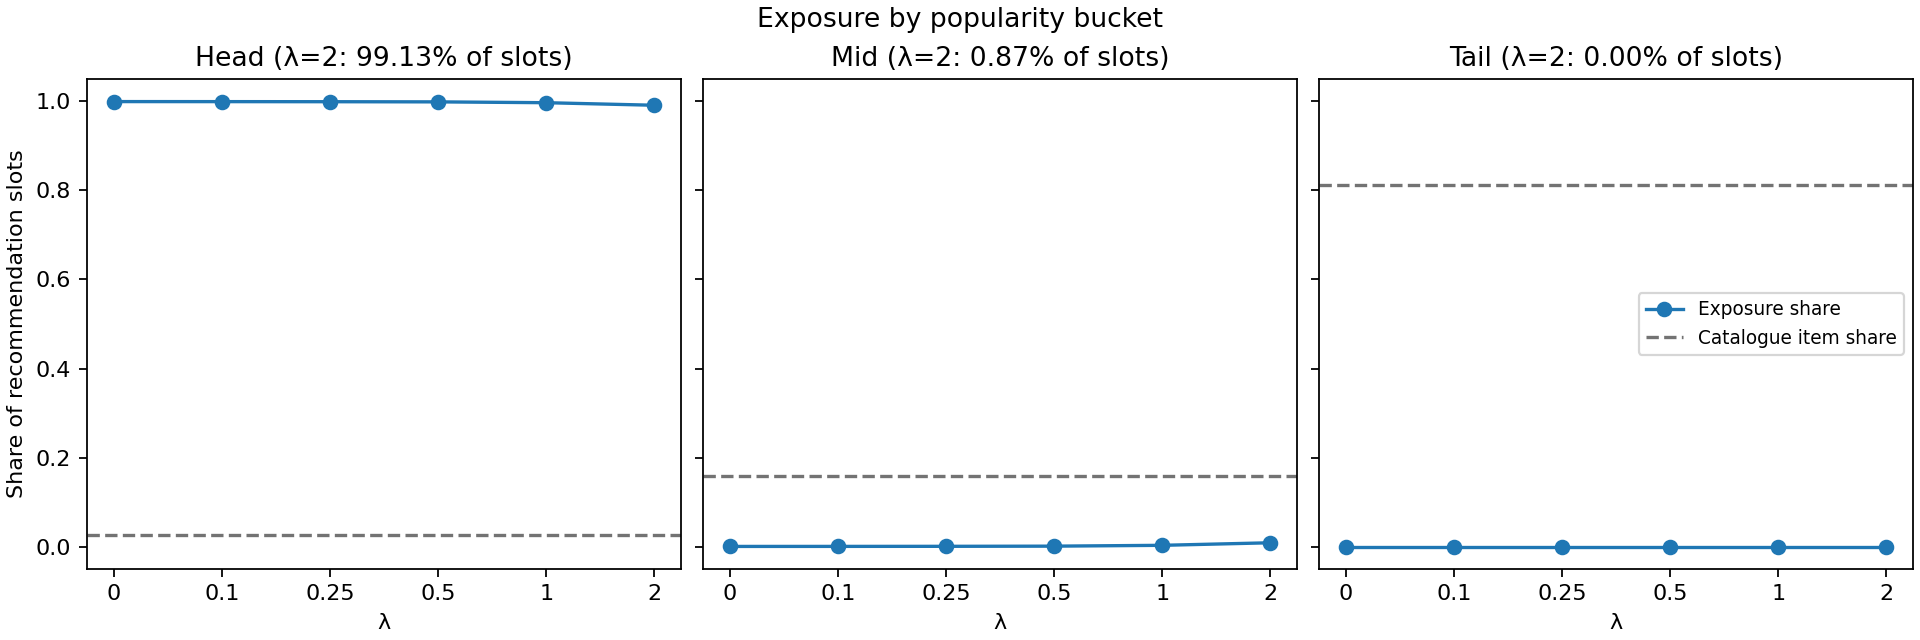

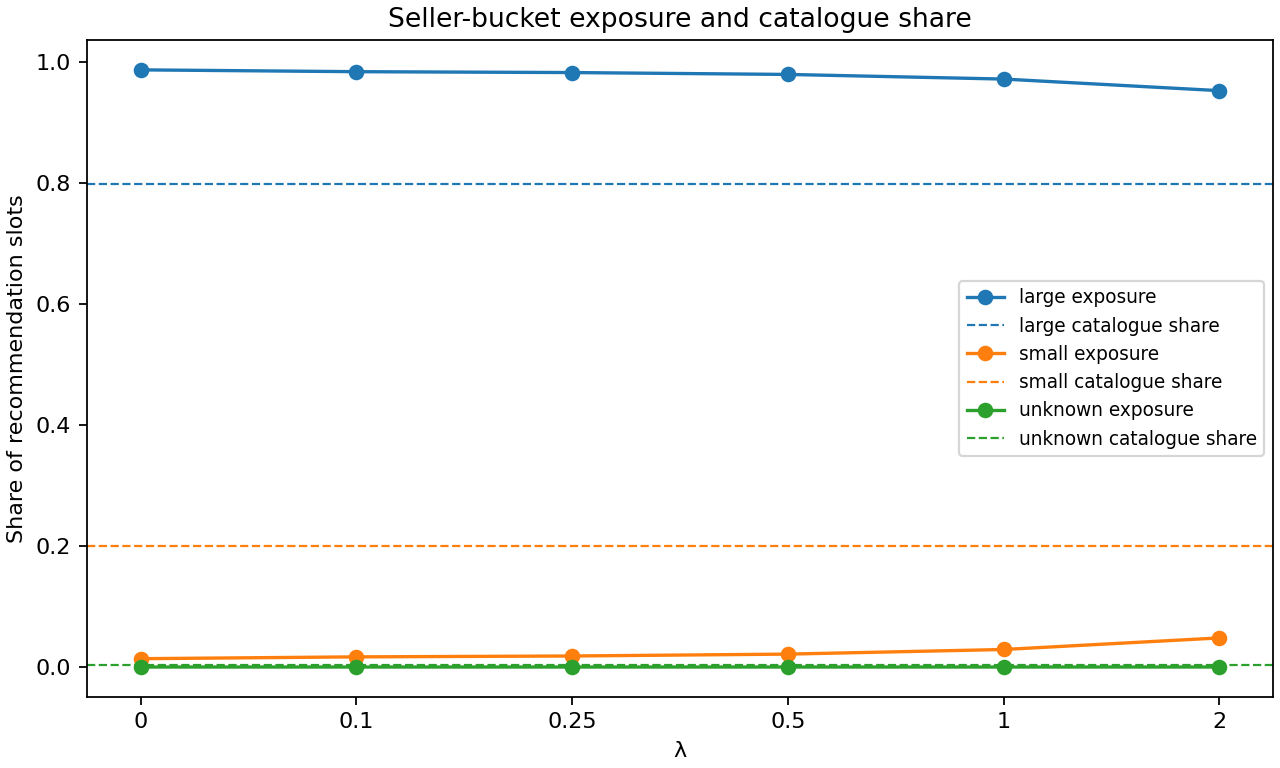

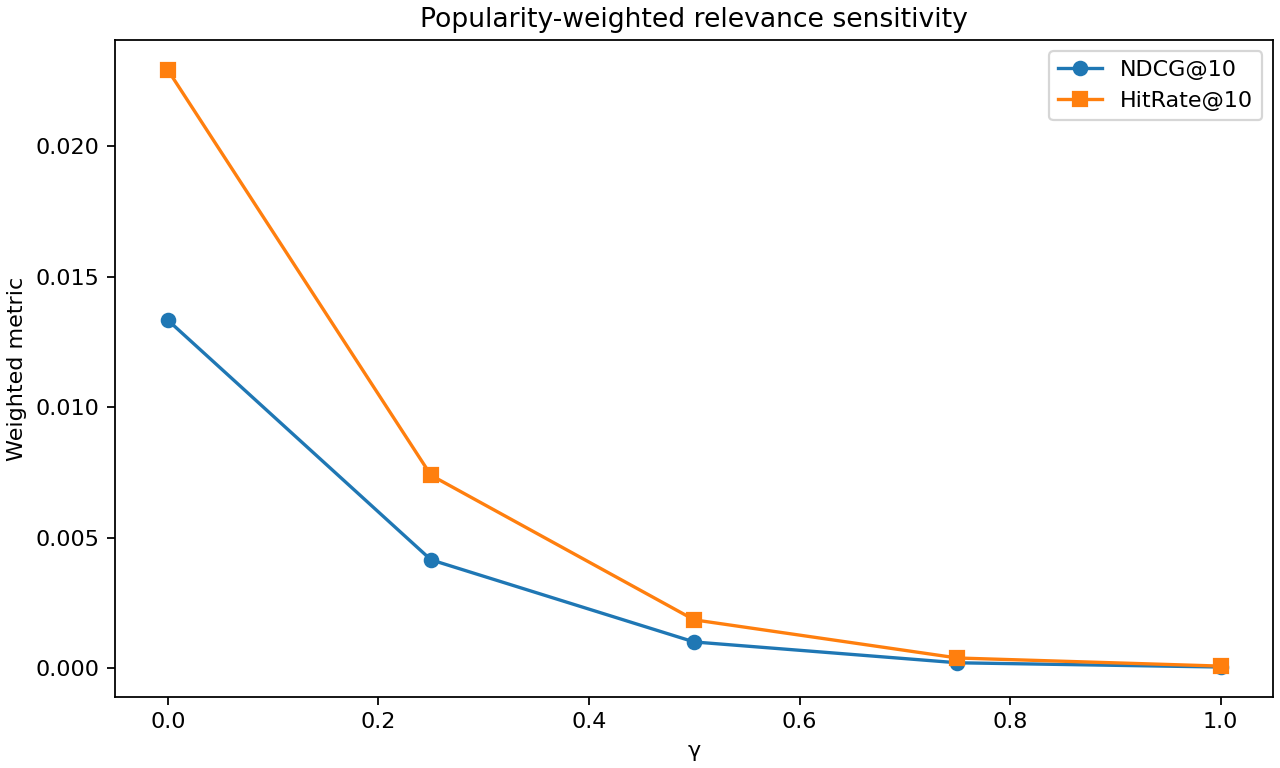

In [14]:
spec = importlib.util.spec_from_file_location("report06", ROOT / "scripts" / "06_report.py")
report06 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(report06)
report06.require_lambda_zero_match(baseline, sweep)   # lambda=0 self-check
FIGURES.mkdir(exist_ok=True)
report06.plot_baseline_quality(baseline, FIGURES / "baseline_relevance.png")
report06.plot_reranker_tradeoff(sweep, sweep.get("chosen_lambda"), FIGURES / "reranker_tradeoff.png")
report06.plot_popularity_exposure(sweep, funnel, FIGURES / "popularity_exposure.png")
report06.plot_store_exposure(sweep, funnel, FIGURES / "store_exposure.png")
names = ["baseline_relevance", "reranker_tradeoff", "popularity_exposure", "store_exposure"]
if sensitivity is not None:
    report06.plot_sensitivity(sensitivity, FIGURES / "sensitivity.png")
    names.append("sensitivity")
for name in names:
    display(Image(filename=str(FIGURES / f"{name}.png")))